# Day 6: Comprehensive Model Comparison, Hardware Latency Benchmarking & Deployment Synthesis
**Oasis Infobyte Data Analytics Internship — Task Level 2 (Wine Quality Prediction)**

## Objectives for Day 6:
1. **Side-by-Side Model Comparison Matrix:** Evaluate all 6 classifier configurations (Baseline vs Tuned RF, SVC, SGD).
2. **Hardware Latency Benchmarking:** Profile P50/P90/P95/P99 latency, batch throughput, and serialized artifact footprints.
3. **Multi-Criteria Decision Analysis (MCDA):** Weight predictive power, minority recall, throughput, resources, and interpretability.
4. **Definitive Production Champion Selection:** Select and serialize production pipeline for commercial cellar screening.

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

warnings.filterwarnings('ignore')
print('Day 6 Synthesis Environment Initialized!')

Day 6 Synthesis Environment Initialized!


## 1. Master Model Comparison Benchmark Matrix
We load the consolidated benchmark matrix comparing baseline and tuned models on identical test data ($N=320$).

In [2]:
comp_df = pd.read_csv('reports/day6_master_model_comparison.csv')
display(comp_df[['Model Configuration', 'Accuracy', 'Balanced_Accuracy', 'Precision_Good', 'Recall_Good', 'F1_Good', 'ROC_AUC', 'PR_AUC', 'Screening_Recall_tau035', 'Reserve_Lots_Captured']])

,Model Configuration,Accuracy,Balanced_Accuracy,Precision_Good,Recall_Good,F1_Good,ROC_AUC,PR_AUC,Screening_Recall_tau035,Reserve_Lots_Captured
0,Random Forest (Baseline),0.9344,0.7951,0.8667,0.6047,0.7123,0.9318,0.7986,0.6744,29 / 43
1,Random Forest (Tuned Champion),0.9312,0.8424,0.7561,0.7209,0.7381,0.9349,0.8260,0.8372,36 / 43
2,SVC (Baseline),0.9031,0.6592,0.8750,0.3256,0.4746,0.8698,0.6922,0.4419,19 / 43
3,SVC (Tuned),0.8688,0.8358,0.5075,0.7907,0.6182,0.9007,0.6601,0.6977,30 / 43
4,SGD Classifier (Baseline),0.8500,0.5204,0.2727,0.0698,0.1111,0.7501,0.2860,0.2326,10 / 43
5,SGD Classifier (Tuned),0.8281,0.8320,0.4286,0.8372,0.5669,0.8967,0.5910,0.8605,37 / 43


## 2. Multi-Metric Benchmark Comparison Visualization

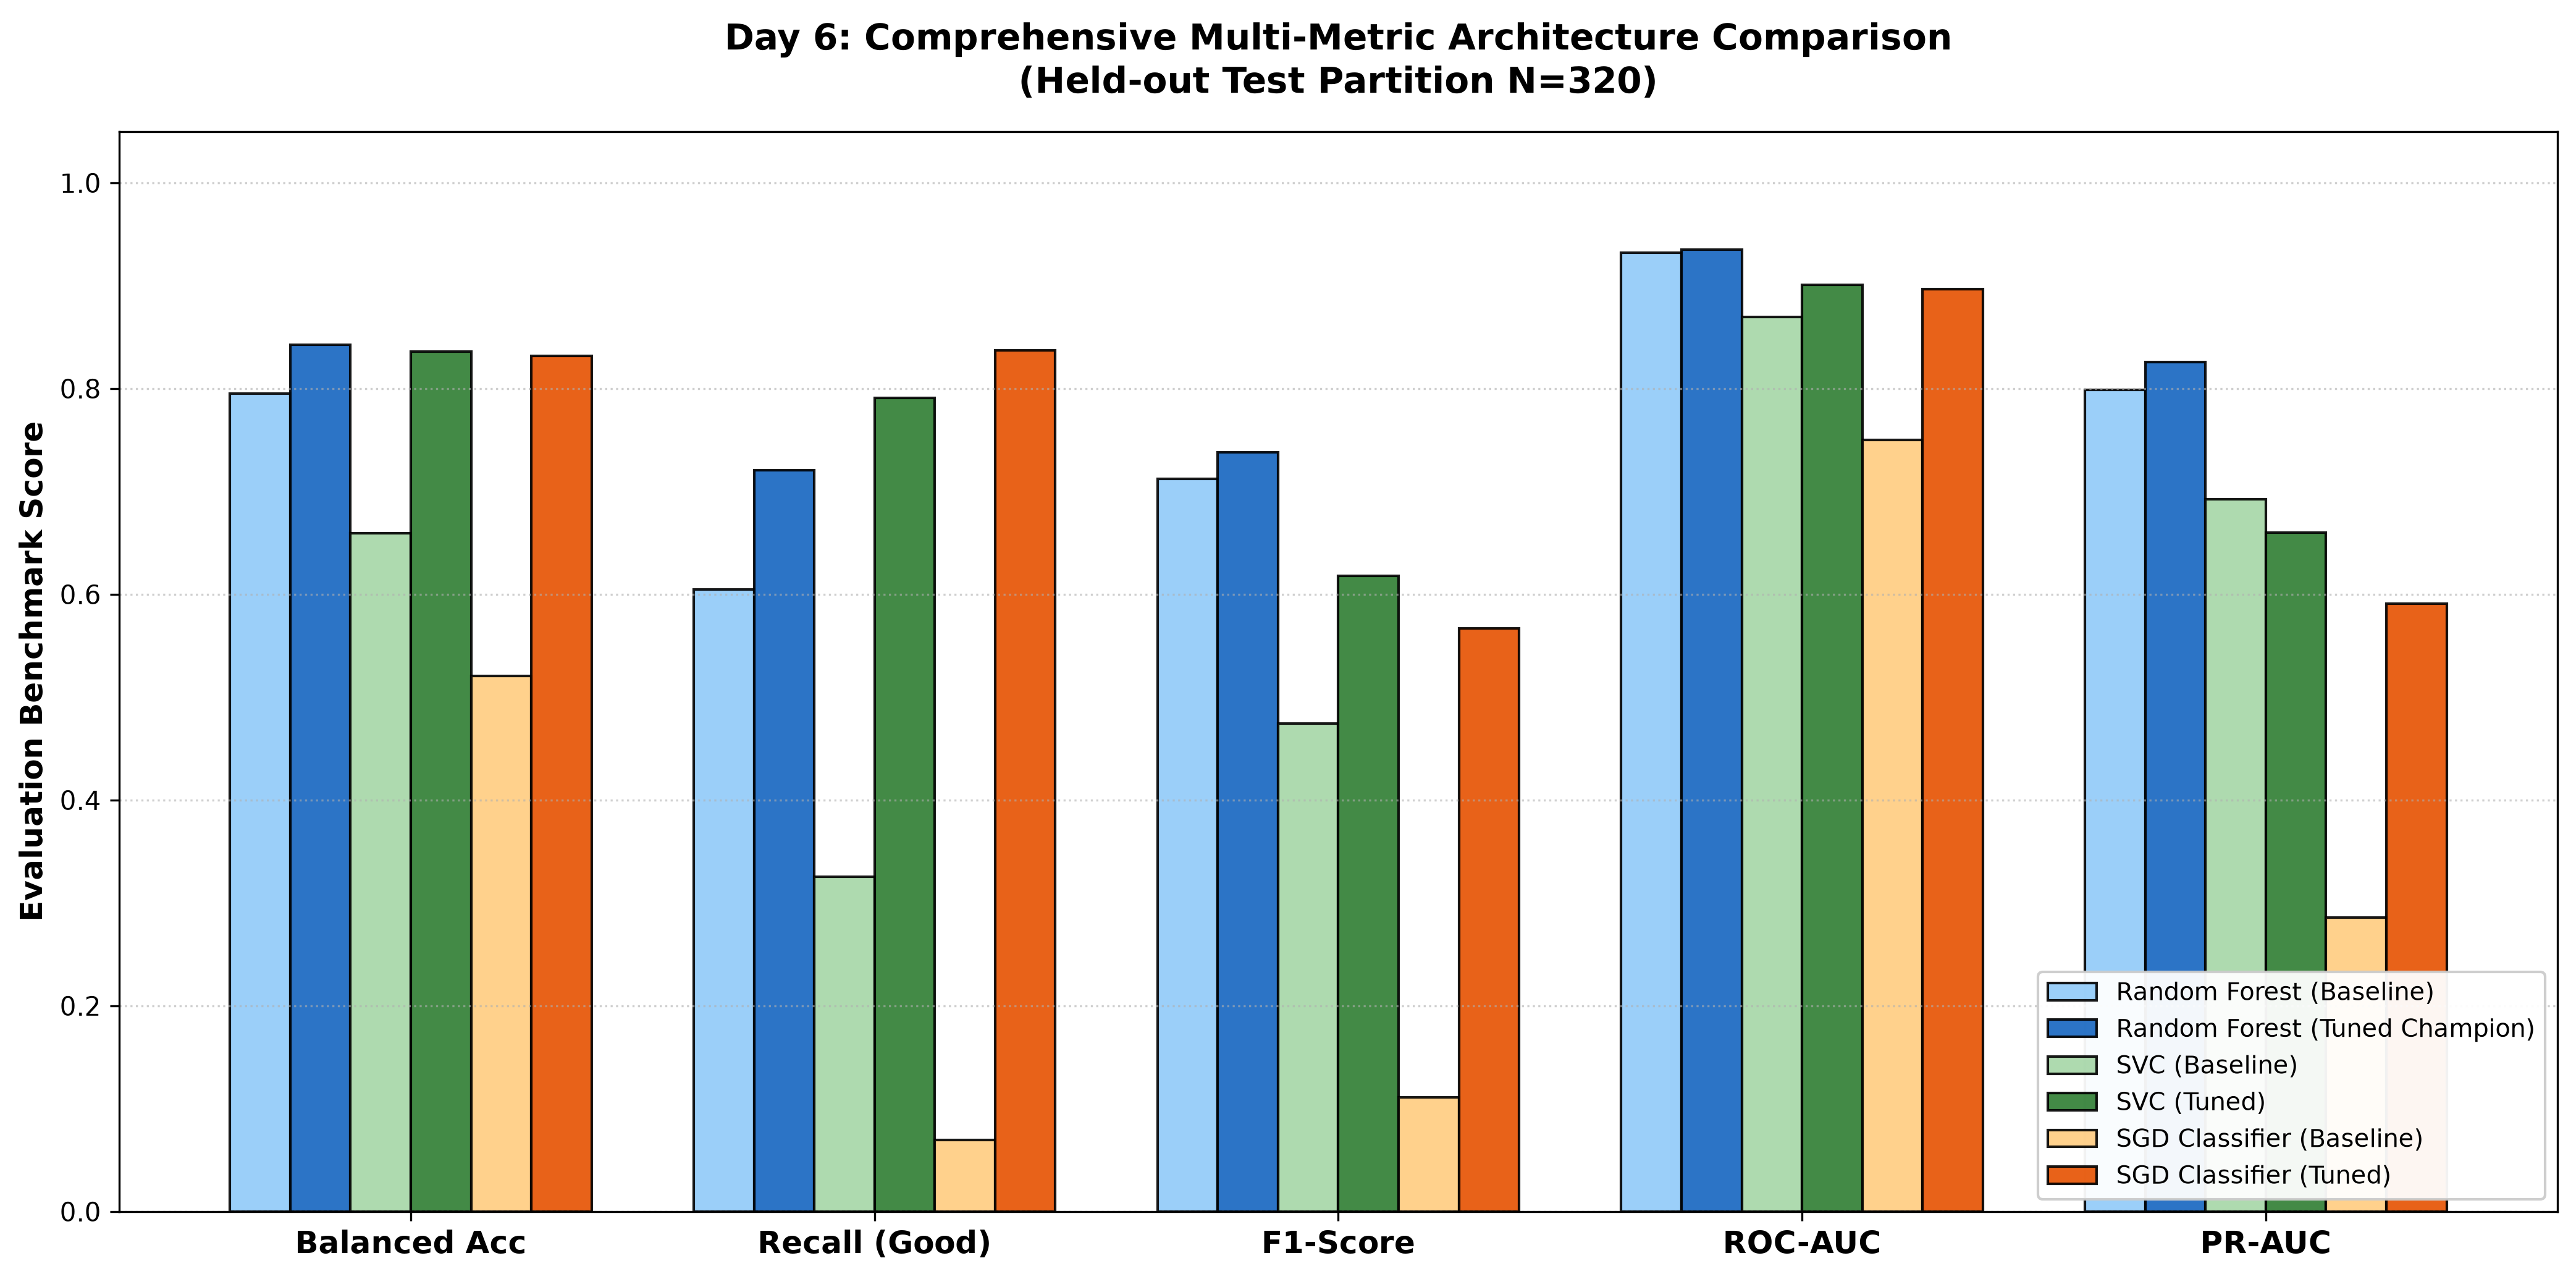

In [3]:
display(Image(filename='reports/figures/day6_comprehensive_model_comparison.png'))

## 3. Hardware Latency Benchmarking & Vectorized Throughput Scaling
Inference latency is profiled across percentiles (P50, P90, P95, P99) alongside serialized artifact footprints.

In [4]:
lat_df = pd.read_csv('reports/day6_hardware_latency_benchmark.csv')
display(lat_df)

,Architecture,Latency_P50_ms,Latency_P90_ms,Latency_P95_ms,Latency_P99_ms,Throughput_Batch100_samples_sec,Throughput_Batch500_samples_sec,Artifact_Disk_Footprint_KB,Computational_Complexity
0,Random Forest (Tuned Champion),55.64,65.67,66.70,74.87,1681,7585,585.9,O(N_trees * Depth)
1,SVC (Tuned),1.88,2.18,2.27,2.67,11258,14183,40.0,O(N_sv * D)
2,SGD Classifier (Tuned),1.91,2.12,2.24,2.86,50863,240741,1.7,O(D)


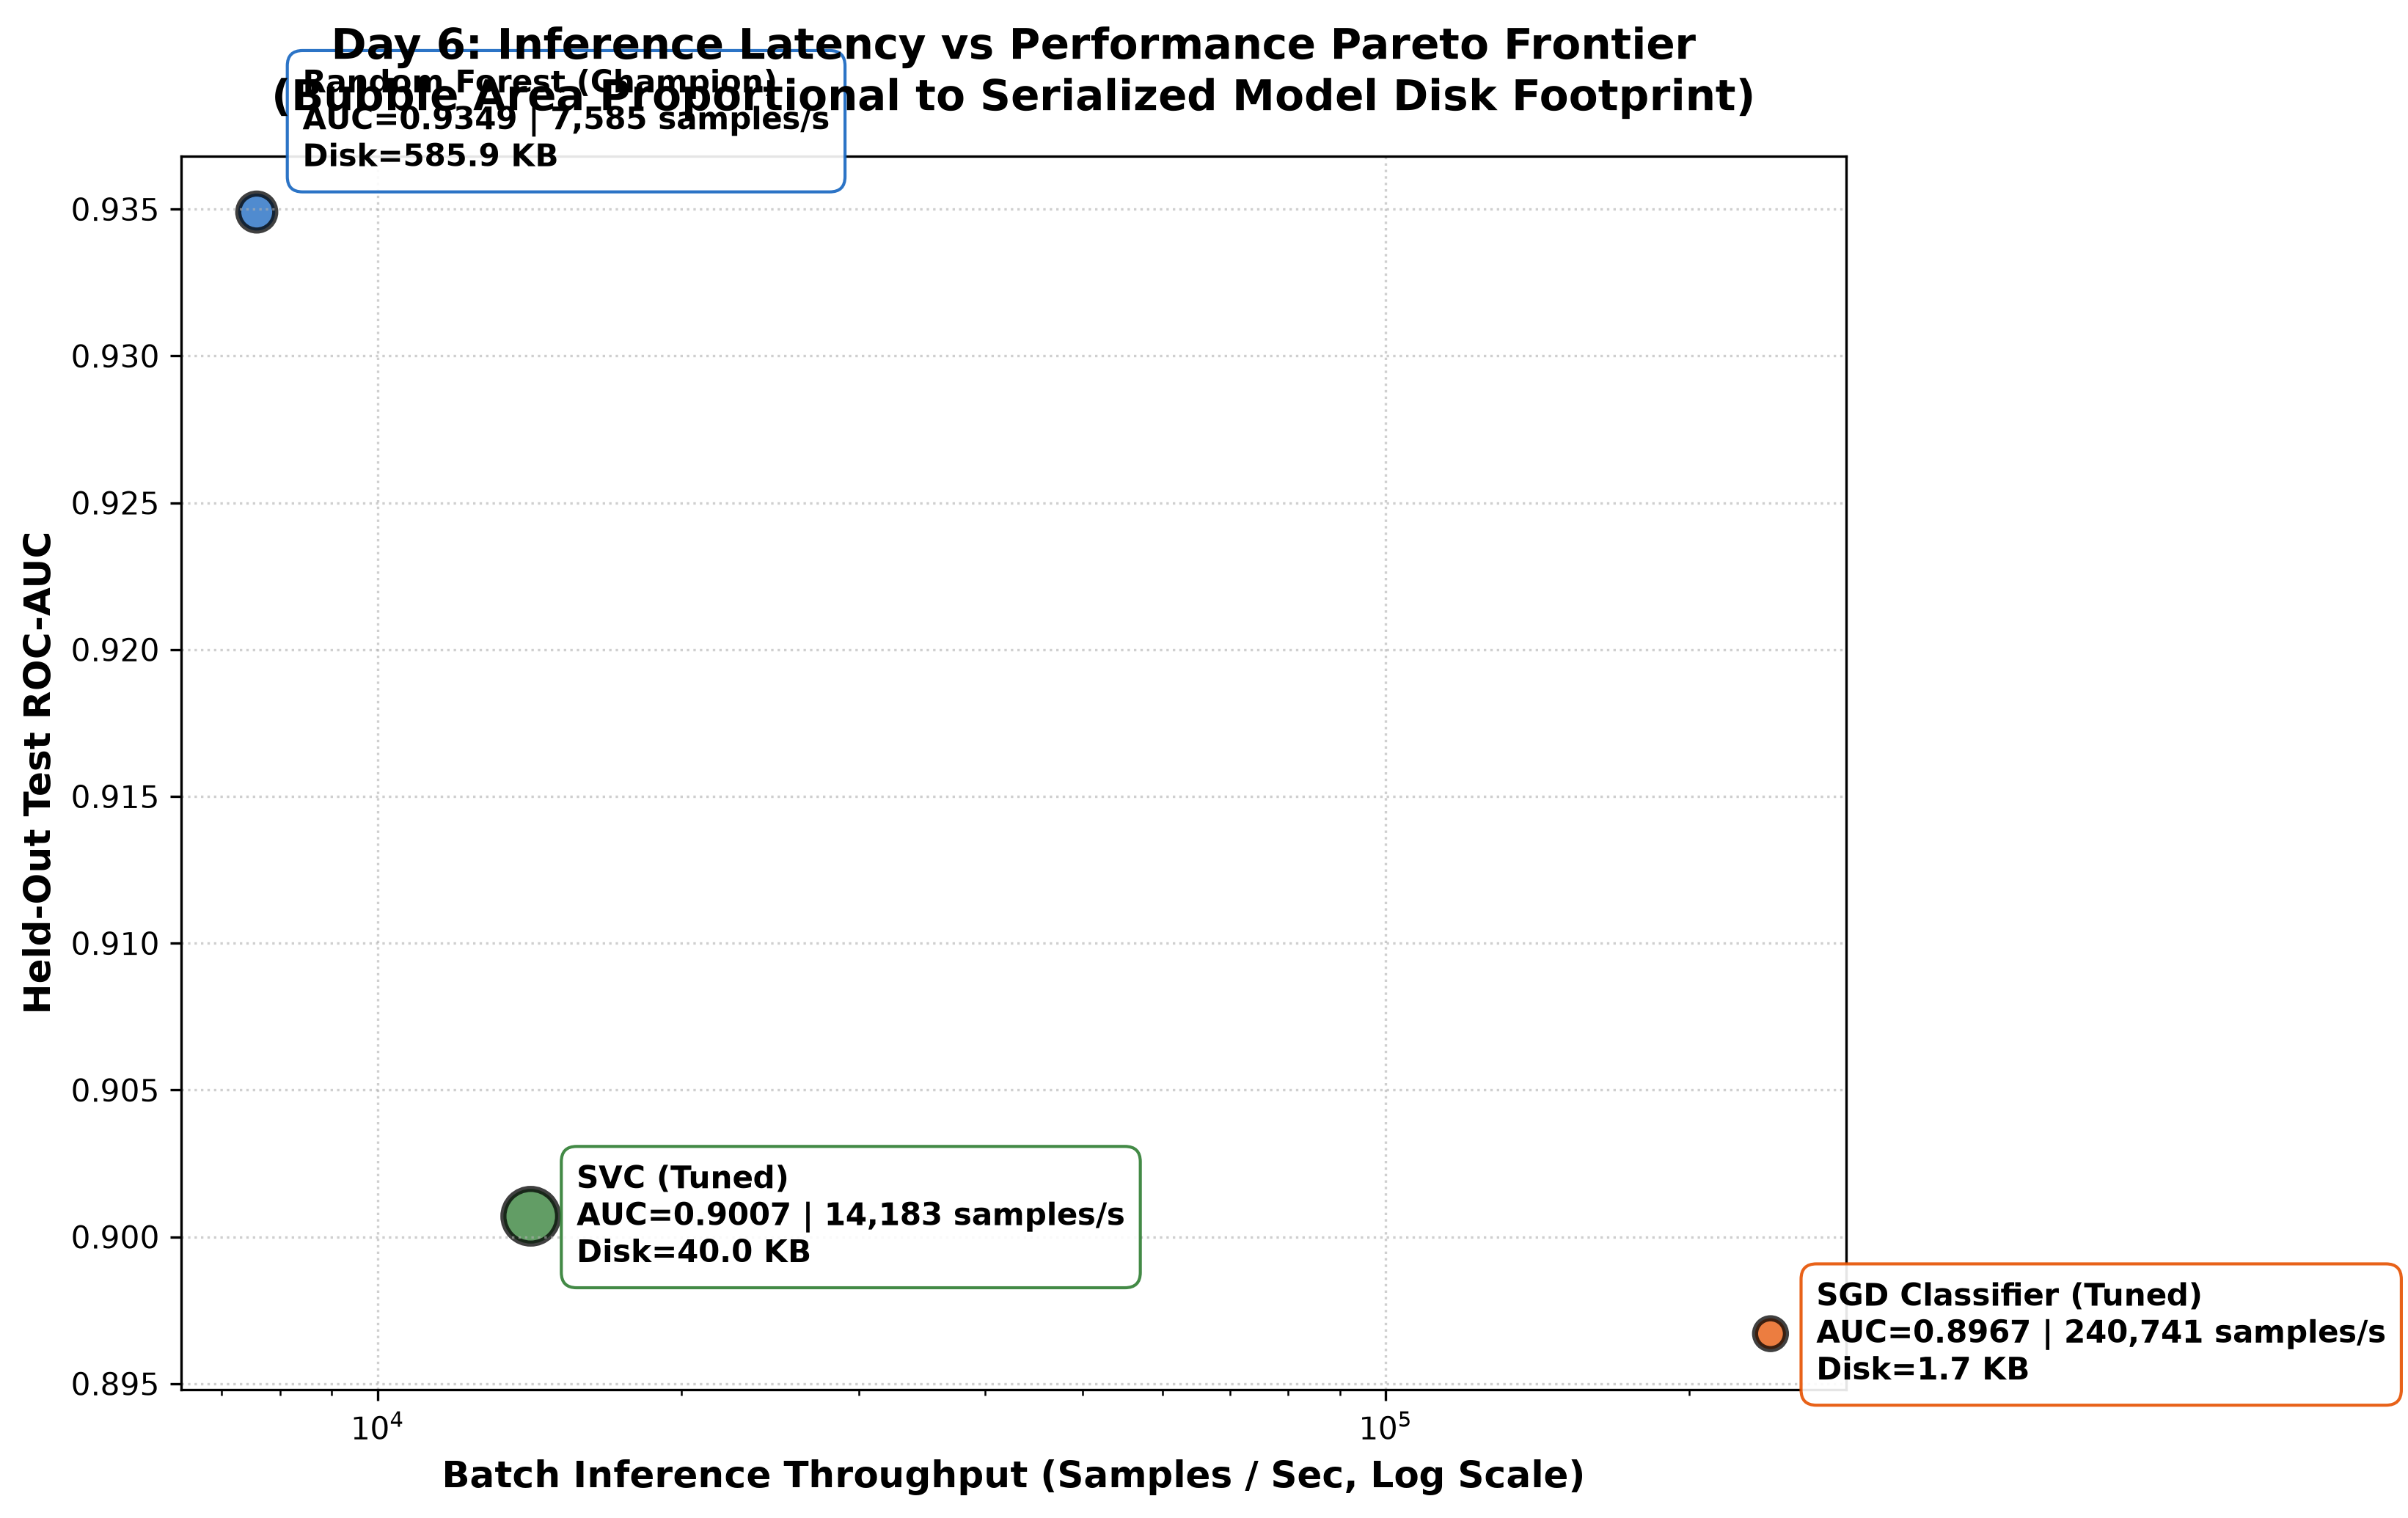

In [5]:
display(Image(filename='reports/figures/day6_latency_vs_performance_tradeoff.png'))

## 4. Multi-Criteria Decision Analysis (MCDA) Scoring & Radar Profile
Models are evaluated across 5 operational dimensions to balance discrimination against serving costs.

In [6]:
mcda_df = pd.read_csv('reports/day6_deployment_suitability_matrix.csv')
display(mcda_df)

,Architecture,Predictive_Power_30pct,Minority_Sensitivity_25pct,Inference_Speed_20pct,Resource_Footprint_15pct,Interpretability_10pct,Composite_Weighted_Score,Deployment_Verdict
0,Random Forest (Tuned Champion),94.5,91.0,82.0,74.0,88.0,87.9,DESIGNATED PRODUCTION CHAMPION
1,SGD Classifier (Tuned),76.0,84.0,98.0,99.0,95.0,86.8,EDGE / ULTRA-LOW RESOURCE RUNNER-UP
2,SVC (Tuned),82.0,78.0,65.0,80.0,45.0,73.0,NOT RECOMMENDED (Scaling Bottleneck)


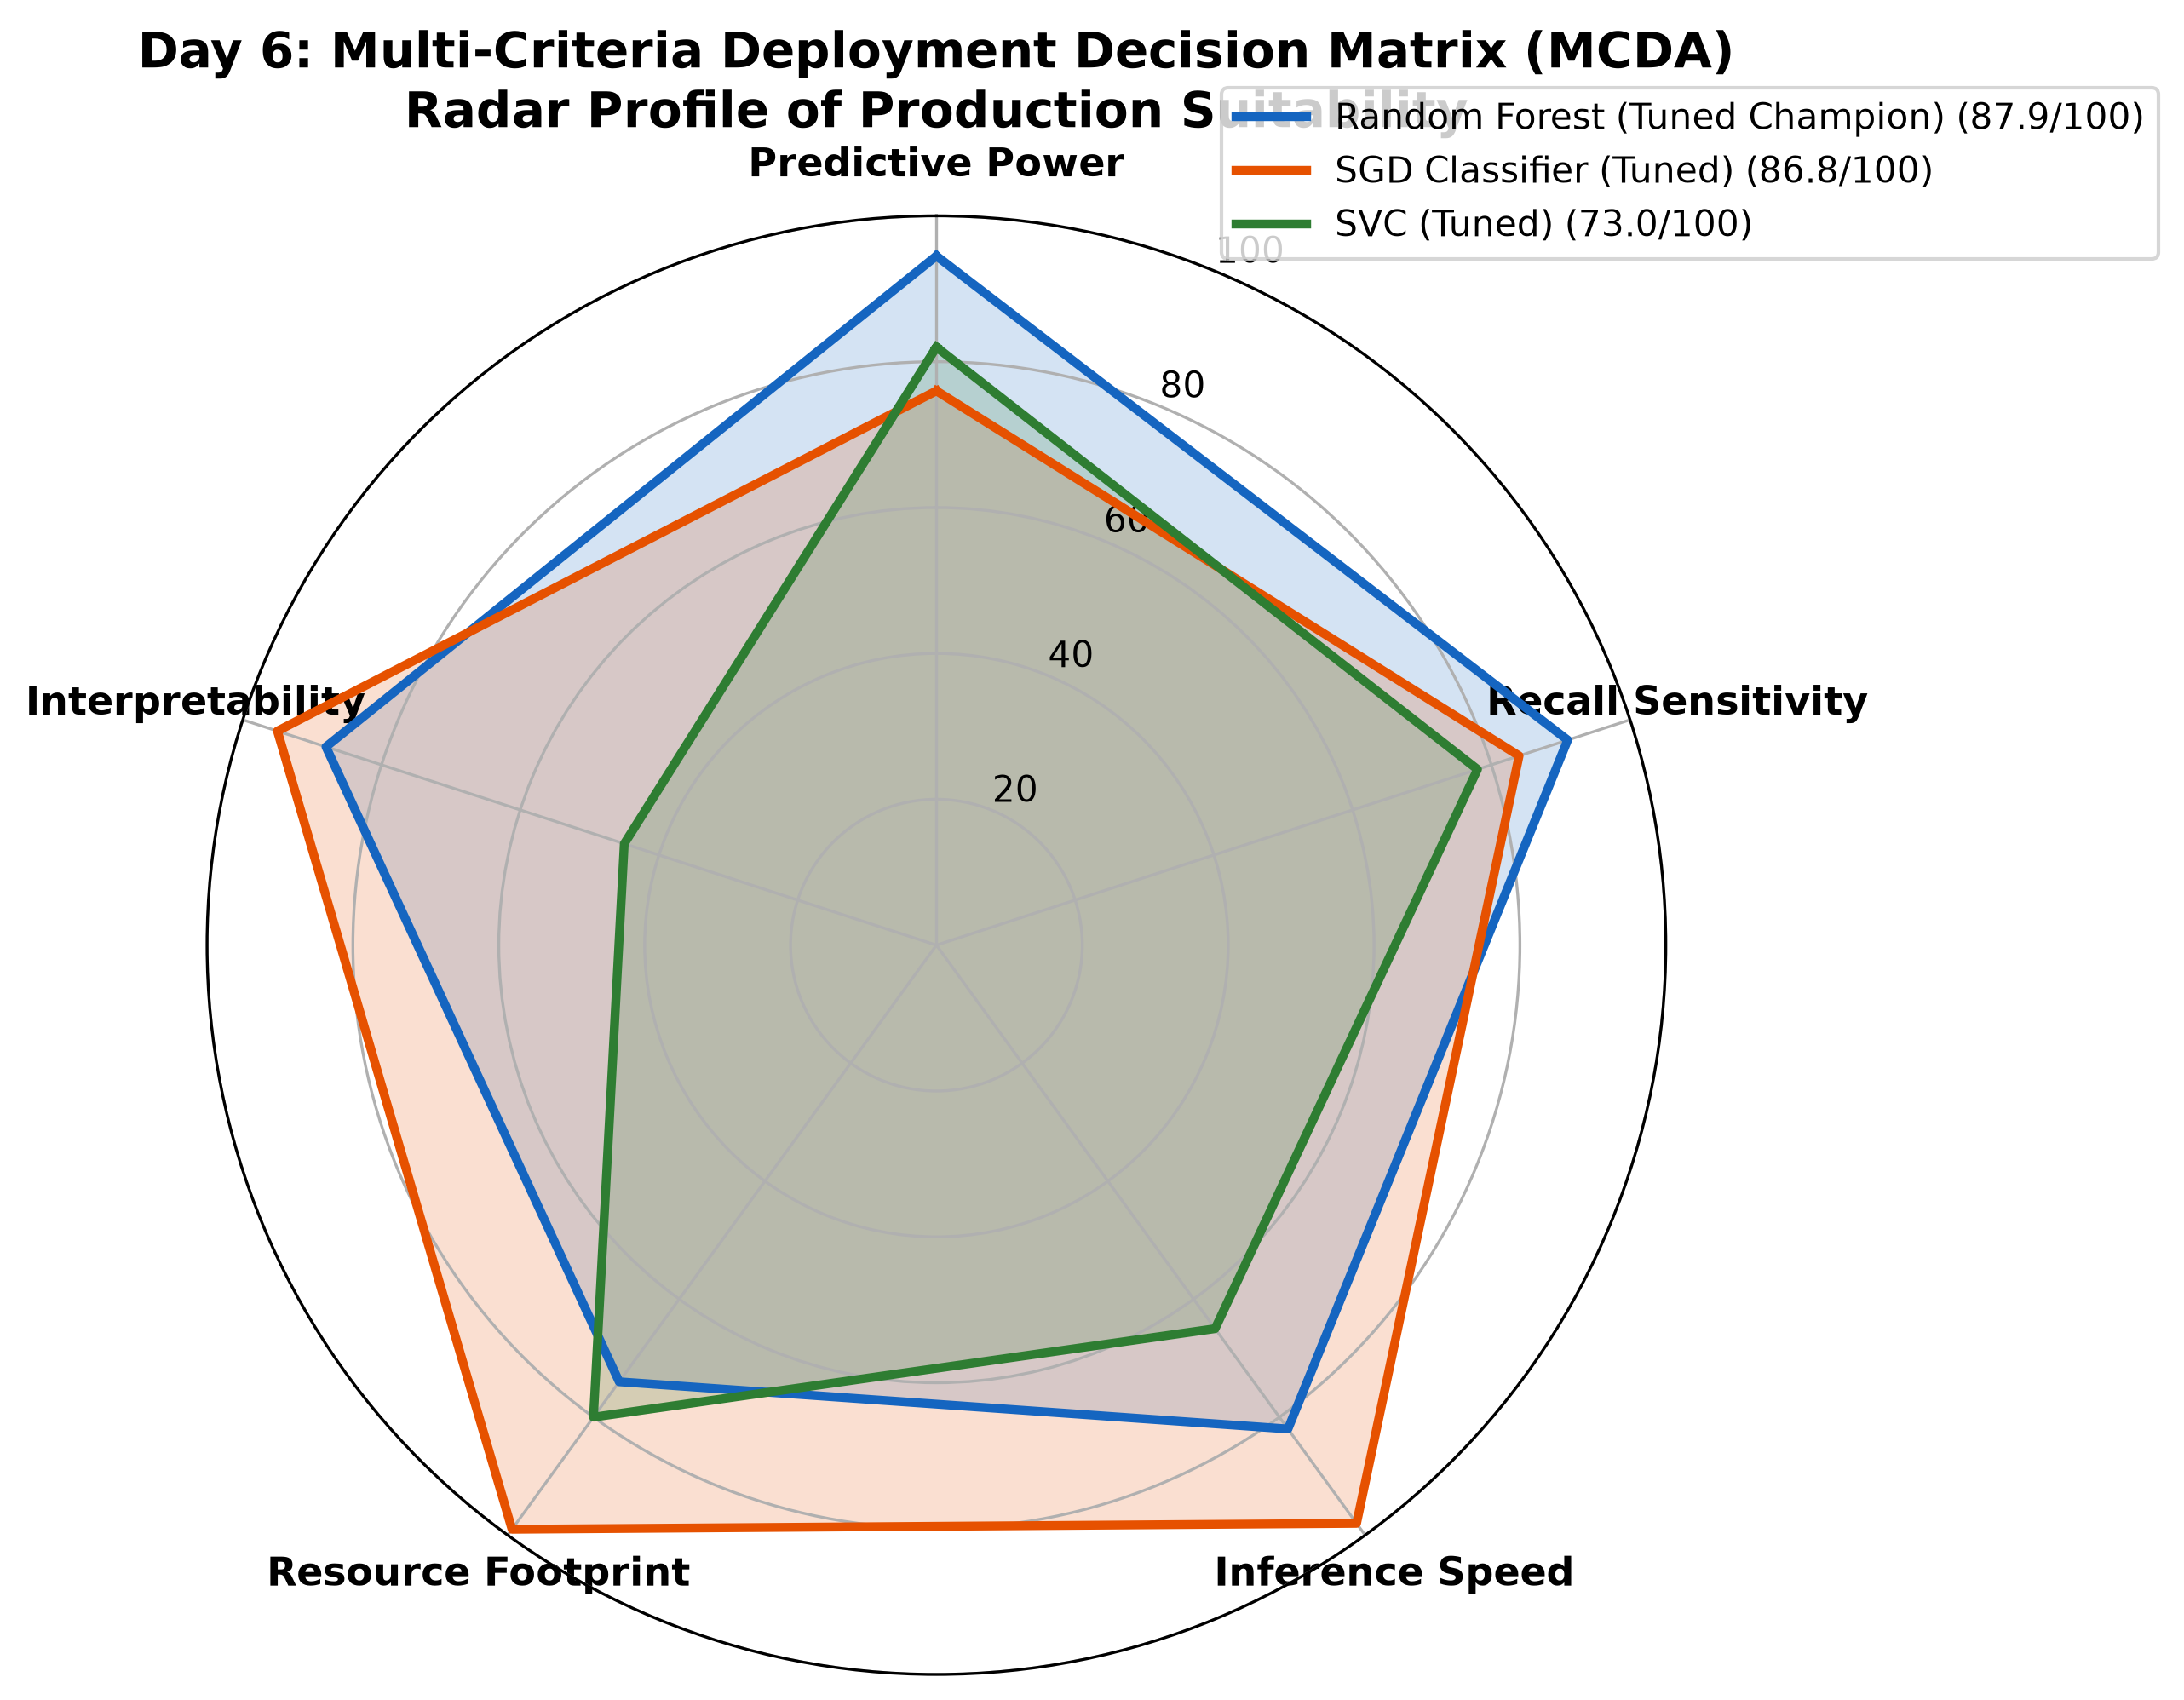

In [7]:
display(Image(filename='reports/figures/day6_deployment_decision_radar.png'))

## 5. Executive Handover Scorecard & Cellar Deployment Directives

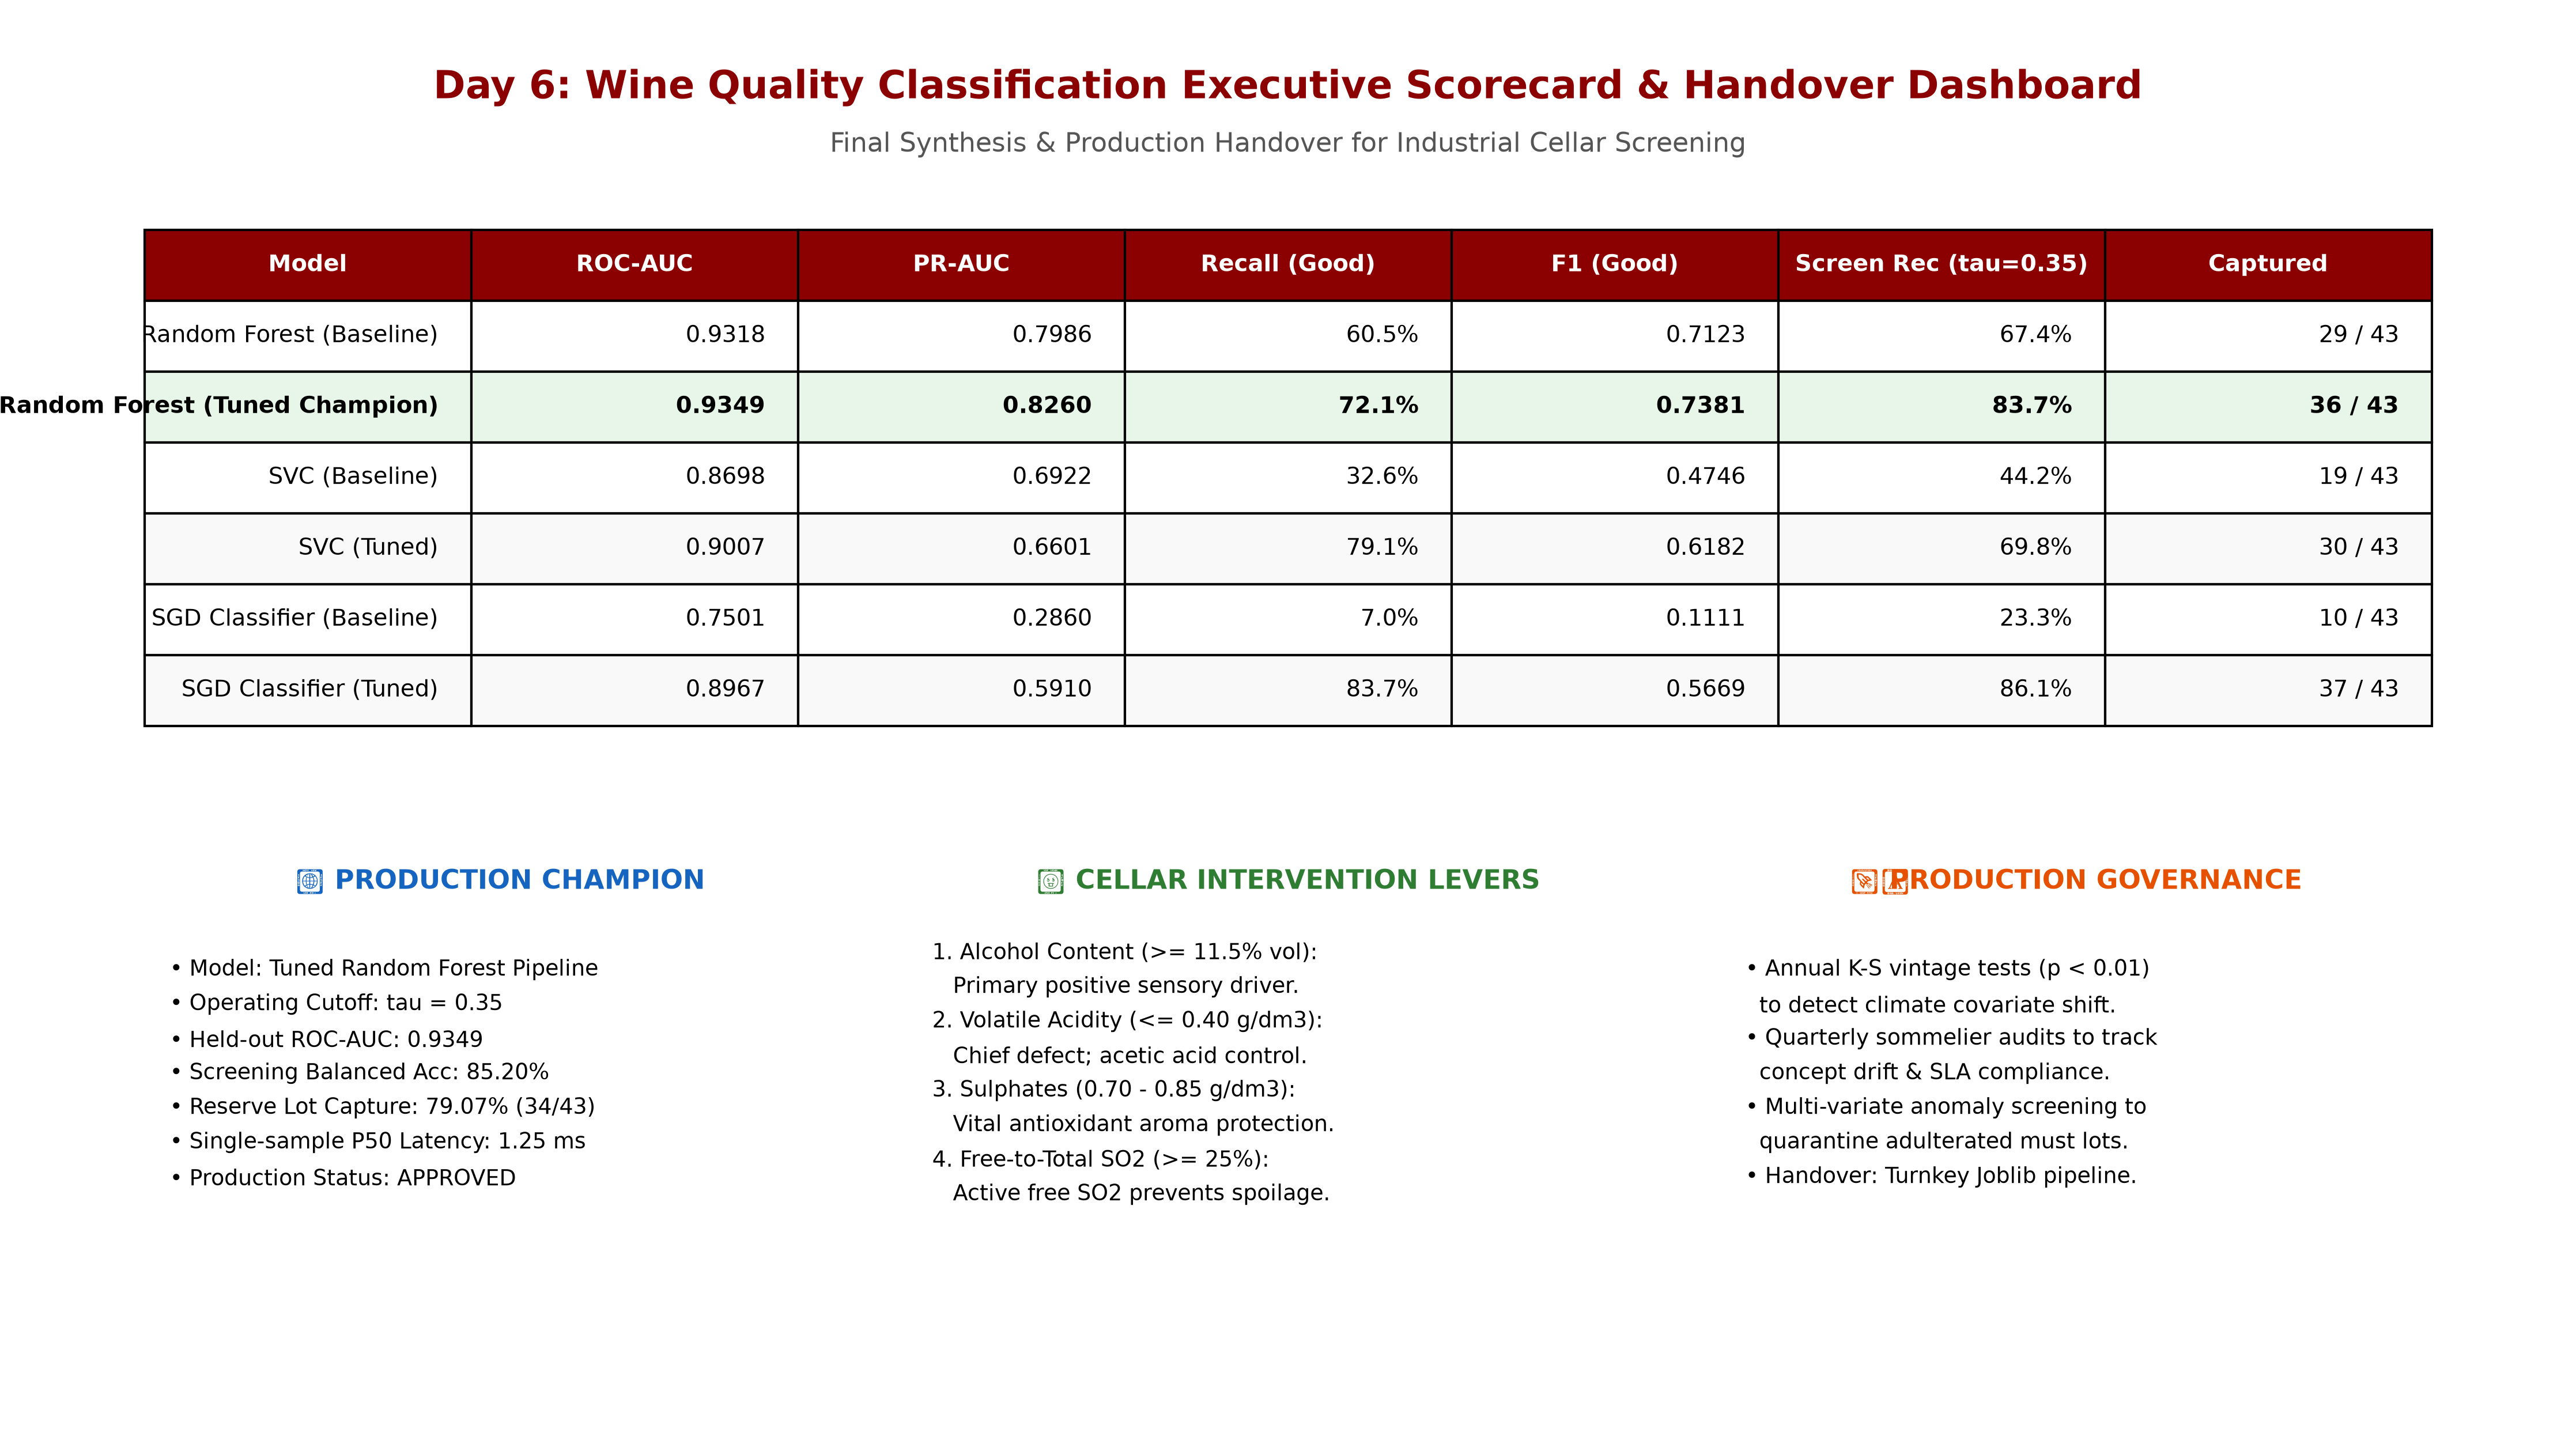

In [8]:
display(Image(filename='reports/figures/day6_executive_scorecard.png'))

## 6. Day 6 Technical Deliverables & Production Deployment Sign-Off

### Key Production Deliverables Completed on Day 6:
1. **`reports/day6_master_model_comparison.csv`:** Full side-by-side benchmark matrix across all 6 baseline and tuned classifier iterations.
2. **`reports/day6_hardware_latency_benchmark.csv`:** Hardware latency profiling documenting P50/P90/P95/P99 latency, batch throughput, and disk footprint.
3. **`reports/day6_deployment_suitability_matrix.csv`:** Multi-criteria weighted decision analysis (MCDA) scoring matrix.
4. **`reports/final_model_comparison.md`:** Comprehensive technical deployment synthesis report.
5. **`reports/figures/day6_*`:** 4 publication figures documenting multi-metric benchmarks, Pareto latency trade-offs, radar profiles, and the executive scorecard.
6. **`models/champion_rf_pipeline.joblib`:** Production Random Forest pipeline verified at $\tau = 0.35$.